# Saúde em Foco — Análise de dados do ABC Paulista

**FIAP | Global Solution 2026.2**  
**Objetivo:** integrar dados populacionais do IBGE (Censo 2022) e registros de estabelecimentos do CNES para os sete municípios do ABC Paulista.

> **Atenção metodológica:** a coluna `CO_IBGE` do arquivo CNES contém o código municipal de seis dígitos. A tabela do IBGE utiliza o código completo de sete dígitos; por isso, o relacionamento é feito pelos seis primeiros dígitos. A contagem inicial de registros não deve ser interpretada automaticamente como quantidade de unidades públicas, ativas ou com atendimento SUS.

## 1. Preparação do ambiente e bibliotecas

Importa as bibliotecas e cria as pastas usadas para armazenar dados brutos e tratados.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import json
import re
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 100)

PASTA_DADOS = Path("dados")
PASTA_BRUTOS = PASTA_DADOS / "brutos"
PASTA_TRATADOS = PASTA_DADOS / "tratados"

PASTA_BRUTOS.mkdir(parents=True, exist_ok=True)
PASTA_TRATADOS.mkdir(parents=True, exist_ok=True)

## 2. Definição dos municípios do ABC Paulista

Cria a tabela de referência com os sete municípios e seus códigos IBGE.

In [2]:
municipios_abc = pd.DataFrame({
    "codigo_ibge": [
        "3513801", "3529401", "3543303", "3544103",
        "3547809", "3548708", "3548807"
    ],
    "municipio": [
        "Diadema", "Mauá", "Ribeirão Pires", "Rio Grande da Serra",
        "Santo André", "São Bernardo do Campo", "São Caetano do Sul"
    ],
    "uf": ["SP"] * 7
})

municipios_abc

,codigo_ibge,municipio,uf
0,3513801,Diadema,SP
1,3529401,Mauá,SP
2,3543303,Ribeirão Pires,SP
3,3544103,Rio Grande da Serra,SP
4,3547809,Santo André,SP
5,3548708,São Bernardo do Campo,SP
6,3548807,São Caetano do Sul,SP


## 3. Consulta da população no IBGE/SIDRA

Obtém a população residente do Censo 2022 para os sete municípios.

In [3]:
arquivo_populacao_local = Path("populacao_abc_censo_2022.csv")
arquivo_populacao_tratada = PASTA_TRATADOS / "populacao_abc_censo_2022.csv"

if arquivo_populacao_local.exists():
    populacao_ibge = pd.read_csv(arquivo_populacao_local, dtype={"codigo_ibge": str})
    print("População carregada do CSV enviado junto ao notebook.")
elif arquivo_populacao_tratada.exists():
    populacao_ibge = pd.read_csv(arquivo_populacao_tratada, dtype={"codigo_ibge": str})
    print("População carregada da pasta de dados tratados.")
else:
    url_sidra = (
        "https://apisidra.ibge.gov.br/values/t/4709/"
        "n6/3513801,3529401,3543303,3544103,3547809,3548708,3548807/"
        "v/93/p/2022"
    )
    resposta = requests.get(url_sidra, timeout=60)
    resposta.raise_for_status()
    dados_sidra = resposta.json()
    populacao_ibge = pd.DataFrame(dados_sidra[1:])

print("Registros populacionais obtidos:", len(populacao_ibge))
display(populacao_ibge.head())

População carregada da pasta de dados tratados.
Registros populacionais obtidos: 7


,codigo_ibge,municipio_ibge,populacao_2022
0,3513801,Diadema (SP),393237
1,3529401,Mauá (SP),418261
2,3543303,Ribeirão Pires (SP),115559
3,3544103,Rio Grande da Serra (SP),44170
4,3547809,Santo André (SP),748919


## 4. Tratamento dos dados populacionais

Padroniza os campos e mantém as colunas necessárias para a integração.

In [4]:
populacao_ibge = populacao_ibge.rename(columns={
    "D1C": "codigo_ibge",
    "D1N": "municipio_ibge",
    "V": "populacao_2022"
})

populacao_ibge["codigo_ibge"] = populacao_ibge["codigo_ibge"].astype(str)
populacao_ibge["populacao_2022"] = pd.to_numeric(
    populacao_ibge["populacao_2022"], errors="coerce"
)

populacao_ibge = populacao_ibge[
    ["codigo_ibge", "municipio_ibge", "populacao_2022"]
].drop_duplicates()

populacao_ibge

,codigo_ibge,municipio_ibge,populacao_2022
0,3513801,Diadema (SP),393237
1,3529401,Mauá (SP),418261
2,3543303,Ribeirão Pires (SP),115559
3,3544103,Rio Grande da Serra (SP),44170
4,3547809,Santo André (SP),748919
5,3548708,São Bernardo do Campo (SP),810729
6,3548807,São Caetano do Sul (SP),165655


## 5. Validação da população municipal

Confere se os sete municípios foram retornados e exporta a base populacional.

In [5]:
# Conferência: esperamos exatamente os sete municípios.
conferencia_ibge = municipios_abc.merge(
    populacao_ibge,
    on="codigo_ibge",
    how="left",
    validate="one_to_one"
)

display(conferencia_ibge)

assert len(conferencia_ibge) == 7, "A consulta não retornou os sete municípios."
assert conferencia_ibge["populacao_2022"].notna().all(), (
    "Há município sem população. Confira a resposta da API SIDRA."
)

populacao_ibge.to_csv(
    PASTA_TRATADOS / "populacao_abc_censo_2022.csv",
    index=False,
    encoding="utf-8-sig"
)

,codigo_ibge,municipio,uf,municipio_ibge,populacao_2022
0,3513801,Diadema,SP,Diadema (SP),393237
1,3529401,Mauá,SP,Mauá (SP),418261
2,3543303,Ribeirão Pires,SP,Ribeirão Pires (SP),115559
3,3544103,Rio Grande da Serra,SP,Rio Grande da Serra (SP),44170
4,3547809,Santo André,SP,Santo André (SP),748919
5,3548708,São Bernardo do Campo,SP,São Bernardo do Campo (SP),810729
6,3548807,São Caetano do Sul,SP,São Caetano do Sul (SP),165655


## 6. Download do arquivo CNES

Baixa o arquivo compactado do CNES quando ele ainda não está disponível localmente.

In [6]:
url_cnes = (
    "https://s3.sa-east-1.amazonaws.com/"
    "ckan.saude.gov.br/CNES/cnes_estabelecimentos_json.zip"
)

# Se o ZIP enviado estiver na mesma pasta do notebook, utiliza esse arquivo.
arquivo_zip_local = Path("cnes_estabelecimentos_json.zip")
arquivo_zip_cnes = arquivo_zip_local if arquivo_zip_local.exists() else (PASTA_BRUTOS / "cnes_estabelecimentos_json.zip")

if not arquivo_zip_cnes.exists():
    with requests.get(url_cnes, stream=True, timeout=180) as resposta:
        resposta.raise_for_status()
        with open(arquivo_zip_cnes, "wb") as arquivo:
            for bloco in resposta.iter_content(chunk_size=1024 * 1024):
                if bloco:
                    arquivo.write(bloco)

print("Arquivo CNES:", arquivo_zip_cnes.resolve())
print(f"Tamanho compactado: {arquivo_zip_cnes.stat().st_size / (1024**2):.1f} MB")

Arquivo CNES: C:\Users\Caue Almiron\Documents\global_fiap\dados\brutos\cnes_estabelecimentos_json.zip
Tamanho compactado: 65.4 MB


## 7. Inspeção do arquivo compactado CNES

Lista o JSON existente no ZIP sem carregar todo o arquivo na memória.

In [7]:
with ZipFile(arquivo_zip_cnes) as z:
    arquivos_json = [nome for nome in z.namelist() if nome.lower().endswith(".json")]
    print("Arquivos JSON encontrados:", arquivos_json)

if not arquivos_json:
    raise ValueError("Não foi encontrado arquivo JSON dentro do ZIP.")

nome_json = arquivos_json[0]
print("Arquivo que será processado:", nome_json)
print("Leitura em fluxo será usada para reduzir o consumo de memória.")

Arquivos JSON encontrados: ['cnes_estabelecimentos.json']
Arquivo que será processado: cnes_estabelecimentos.json
Leitura em fluxo será usada para reduzir o consumo de memória.


## 8. Extração e normalização dos registros CNES

Lê o JSON em fluxo e mantém apenas os registros dos municípios do ABC Paulista.

In [8]:
# Instale ijson uma única vez, se necessário: %pip install ijson
import ijson

# CO_IBGE no arquivo CNES possui seis dígitos; o código IBGE completo possui sete.
codigos_abc_6 = set(municipios_abc["codigo_ibge"].astype(str).str[:6])
registros_abc = []

with ZipFile(arquivo_zip_cnes) as z:
    with z.open(nome_json) as arquivo_json:
        for registro in ijson.items(arquivo_json, "item"):
            codigo = str(registro.get("CO_IBGE", "")).strip()
            if codigo in codigos_abc_6:
                registros_abc.append(registro)

cnes_abc = pd.DataFrame(registros_abc)
print("Dimensão da base filtrada:", cnes_abc.shape)
print("Colunas disponíveis:", cnes_abc.columns.tolist())
display(cnes_abc.head(3))

Dimensão da base filtrada: (6290, 36)
Colunas disponíveis: ['CO_CNES', 'CO_UNIDADE', 'CO_UF', 'CO_IBGE', 'NU_CNPJ_MANTENEDORA', 'NO_RAZAO_SOCIAL', 'NO_FANTASIA', 'CO_NATUREZA_ORGANIZACAO', 'DS_NATUREZA_ORGANIZACAO', 'TP_GESTAO', 'CO_NIVEL_HIERARQUIA', 'DS_NIVEL_HIERARQUIA', 'CO_ESFERA_ADMINISTRATIVA', 'DS_ESFERA_ADMINISTRATIVA', 'CO_ATIVIDADE', 'TP_UNIDADE', 'CO_CEP', 'NO_LOGRADOURO', 'NU_ENDERECO', 'NO_BAIRRO', 'NU_TELEFONE', 'NU_LATITUDE', 'NU_LONGITUDE', 'CO_TURNO_ATENDIMENTO', 'DS_TURNO_ATENDIMENTO', 'NU_CNPJ', 'NO_EMAIL', 'CO_NATUREZA_JUR', 'ST_CENTRO_CIRURGICO', 'ST_CENTRO_OBSTETRICO', 'ST_CENTRO_NEONATAL', 'ST_ATEND_HOSPITALAR', 'ST_SERVICO_APOIO', 'ST_ATEND_AMBULATORIAL', 'CO_MOTIVO_DESAB', 'CO_AMBULATORIAL_SUS']


,CO_CNES,CO_UNIDADE,CO_UF,CO_IBGE,NU_CNPJ_MANTENEDORA,NO_RAZAO_SOCIAL,NO_FANTASIA,CO_NATUREZA_ORGANIZACAO,DS_NATUREZA_ORGANIZACAO,TP_GESTAO,CO_NIVEL_HIERARQUIA,DS_NIVEL_HIERARQUIA,CO_ESFERA_ADMINISTRATIVA,DS_ESFERA_ADMINISTRATIVA,CO_ATIVIDADE,TP_UNIDADE,CO_CEP,NO_LOGRADOURO,NU_ENDERECO,NO_BAIRRO,NU_TELEFONE,NU_LATITUDE,NU_LONGITUDE,CO_TURNO_ATENDIMENTO,DS_TURNO_ATENDIMENTO,NU_CNPJ,NO_EMAIL,CO_NATUREZA_JUR,ST_CENTRO_CIRURGICO,ST_CENTRO_OBSTETRICO,ST_CENTRO_NEONATAL,ST_ATEND_HOSPITALAR,ST_SERVICO_APOIO,ST_ATEND_AMBULATORIAL,CO_MOTIVO_DESAB,CO_AMBULATORIAL_SUS
0,8486,3547800008486,35,354780,46522942000130,MUNICIPIO DE SANTO ANDRE,CENTRO MEDICO DE ESPECIALIDADES JOAQUIM TAVORA,,,M,,,M,MUNICIPAL,04,4,09030390,RUA JOAQUIM TAVORA,134,VILA ASSUNCAO,(11) 4435-1284,-23.6681857,-46.5248083,04,"ATENDIMENTO NOS TURNOS DA MANHA, TARDE E NOITE",,,1244,0.0,0.0,0.0,0.0,1.0,0.0,10,SIM
1,8494,3547800008494,35,354780,46522942000130,PREFEITURA MUNICIPAL DE SANTO ANDRE,UPA BANGU,,,M,,,M,MUNICIPAL,04,73,09210240,RUA AVARE,107,VILA SAO PEDRO,(11)49964646,-23.6411957,-46.5274164,06,"ATENDIMENTO CONTINUO DE 24 HORAS/DIA (PLANTAO:INCLUI SABADOS, DOMINGOS E FERIADOS)",,,1244,0.0,0.0,0.0,0.0,1.0,1.0,,SIM
2,8508,3547800008508,35,354780,46522942000130,PREFEITURA MUNICIPAL DE SANTO ANDRE,UBS DR MOYSES FUCS,,,M,,,M,MUNICIPAL,03,2,09240200,RUA ALEXANDRETA,180,JARDIM SANTO ANTONIO,(11) 4435-1373,-23.6282563,-46.5223628,04,"ATENDIMENTO NOS TURNOS DA MANHA, TARDE E NOITE",,,1244,0.0,0.0,0.0,0.0,1.0,0.0,,SIM


## 9. Conferência do campo de identificação municipal

Confirma que o campo CO_IBGE foi localizado e mostra exemplos dos códigos.

In [9]:
coluna_codigo_cnes = "CO_IBGE"

print("Coluna identificadora encontrada:", coluna_codigo_cnes)
print("Colunas relacionadas a município/IBGE:")
print([col for col in cnes_abc.columns if "mun" in str(col).lower() or "ibge" in str(col).lower()])

Coluna identificadora encontrada: CO_IBGE
Colunas relacionadas a município/IBGE:
['CO_IBGE']


## 10. Padronização dos códigos municipais

Converte o CO_IBGE de seis dígitos e prepara a chave de relacionamento com o IBGE.

In [10]:
print("Tipo de dado:", cnes_abc["CO_IBGE"].dtype)
display(cnes_abc[["CO_IBGE"]].head(10))
print("Municípios distintos no recorte:", cnes_abc["CO_IBGE"].nunique())

Tipo de dado: object


,CO_IBGE
0,354780
1,354780
2,354780
3,354780
4,354780
5,354780
6,354780
7,354780
8,354780
9,354780


Municípios distintos no recorte: 7


## 11. Contagem de registros CNES por município

Conta os registros encontrados em cada município e verifica a cobertura territorial.

In [11]:
# O CNES utiliza o código municipal de seis dígitos (sem o dígito verificador do IBGE).
cnes_abc["CO_IBGE"] = (
    cnes_abc["CO_IBGE"].astype("string").str.strip().str.zfill(6)
)

municipios_abc["codigo_ibge"] = municipios_abc["codigo_ibge"].astype("string").str.zfill(7)
municipios_abc["codigo_cnes_6"] = municipios_abc["codigo_ibge"].str[:6]

cnes_abc = cnes_abc.merge(
    municipios_abc[["codigo_ibge", "codigo_cnes_6", "municipio"]],
    left_on="CO_IBGE", right_on="codigo_cnes_6", how="left", validate="many_to_one"
)

print("Registros associados a municípios:", cnes_abc["municipio"].notna().sum())
display(cnes_abc[["CO_IBGE", "codigo_ibge", "municipio"]].head())

Registros associados a municípios: 6290


,CO_IBGE,codigo_ibge,municipio
0,354780,3547809,Santo André
1,354780,3547809,Santo André
2,354780,3547809,Santo André
3,354780,3547809,Santo André
4,354780,3547809,Santo André


## 12. Integração dos dados e cálculo do indicador

Combina a contagem CNES com a população e calcula registros por 10 mil habitantes.

In [12]:
contagem_cnes = (
    cnes_abc.groupby(["codigo_ibge", "municipio"], as_index=False)
    .agg(quantidade_registros=("CO_CNES", "nunique"))
)

conferencia_municipios = municipios_abc.merge(
    contagem_cnes, on=["codigo_ibge", "municipio"], how="left"
)
conferencia_municipios["quantidade_registros"] = (
    conferencia_municipios["quantidade_registros"].fillna(0).astype(int)
)

display(conferencia_municipios)
print("Municípios com registros:", (conferencia_municipios["quantidade_registros"] > 0).sum(), "de 7")

,codigo_ibge,municipio,uf,codigo_cnes_6,quantidade_registros
0,3513801,Diadema,SP,351380,366
1,3529401,Mauá,SP,352940,535
2,3543303,Ribeirão Pires,SP,354330,170
3,3544103,Rio Grande da Serra,SP,354410,40
4,3547809,Santo André,SP,354780,1721
5,3548708,São Bernardo do Campo,SP,354870,1954
6,3548807,São Caetano do Sul,SP,354880,1504


Municípios com registros: 7 de 7


## 13. Exportação das bases tratadas

Salva os resultados intermediários para análises futuras e uso no Streamlit.

In [13]:
base_municipal = conferencia_municipios.merge(
    populacao_ibge[["codigo_ibge", "populacao_2022"]],
    on="codigo_ibge", how="left"
)

base_municipal["registros_cnes_por_10mil_hab"] = (
    base_municipal["quantidade_registros"] / base_municipal["populacao_2022"] * 10000
)

display(base_municipal)

# Exporta os resultados para a pasta de dados tratados.
base_municipal.to_csv(PASTA_TRATADOS / "base_municipal_saude_em_foco.csv", index=False, encoding="utf-8-sig")
cnes_abc.to_csv(PASTA_TRATADOS / "cnes_estabelecimentos_abc.csv", index=False, encoding="utf-8-sig")
print("Bases exportadas para:", PASTA_TRATADOS.resolve())

,codigo_ibge,municipio,uf,codigo_cnes_6,quantidade_registros,populacao_2022,registros_cnes_por_10mil_hab
0,3513801,Diadema,SP,351380,366,393237,9.307364
1,3529401,Mauá,SP,352940,535,418261,12.791056
2,3543303,Ribeirão Pires,SP,354330,170,115559,14.711100
3,3544103,Rio Grande da Serra,SP,354410,40,44170,9.055920
4,3547809,Santo André,SP,354780,1721,748919,22.979788
5,3548708,São Bernardo do Campo,SP,354870,1954,810729,24.101765
6,3548807,São Caetano do Sul,SP,354880,1504,165655,90.791102


Bases exportadas para: C:\Users\Caue Almiron\Documents\global_fiap\dados\tratados


## Observações metodológicas e próximos passos

- A contagem inicial inclui os registros CNES encontrados no território; ainda não aplica filtros de situação cadastral.
- A natureza pública/privada deve ser classificada após inspeção dos campos de esfera administrativa/natureza jurídica.
- `CO_AMBULATORIAL_SUS` não equivale à natureza pública do estabelecimento.
- Quantidade de estabelecimentos não mede capacidade, qualidade ou acesso efetivo.
- O CNES e o Censo 2022 podem ter períodos de referência diferentes; documente a data de referência do arquivo CNES.
- A análise atual é municipal e não sustenta conclusões por bairro.

**Próxima etapa:** validar os campos do CNES para classificar estabelecimentos e, só então, recalcular os indicadores com filtros documentados.

## 14. Auditoria da estrutura do CNES

Nesta etapa, verificamos as colunas disponíveis, identificamos campos úteis para caracterizar os estabelecimentos e conferimos a unicidade dos códigos CNES.

**Resultado já observado na execução:** 6.290 registros, 6.290 códigos CNES únicos e nenhuma duplicidade por `CO_CNES`.

In [14]:
# 1. Visualizar todas as colunas disponíveis
print("Quantidade de colunas:", len(cnes_abc.columns))

for coluna in cnes_abc.columns:
    print(coluna)

Quantidade de colunas: 39
CO_CNES
CO_UNIDADE
CO_UF
CO_IBGE
NU_CNPJ_MANTENEDORA
NO_RAZAO_SOCIAL
NO_FANTASIA
CO_NATUREZA_ORGANIZACAO
DS_NATUREZA_ORGANIZACAO
TP_GESTAO
CO_NIVEL_HIERARQUIA
DS_NIVEL_HIERARQUIA
CO_ESFERA_ADMINISTRATIVA
DS_ESFERA_ADMINISTRATIVA
CO_ATIVIDADE
TP_UNIDADE
CO_CEP
NO_LOGRADOURO
NU_ENDERECO
NO_BAIRRO
NU_TELEFONE
NU_LATITUDE
NU_LONGITUDE
CO_TURNO_ATENDIMENTO
DS_TURNO_ATENDIMENTO
NU_CNPJ
NO_EMAIL
CO_NATUREZA_JUR
ST_CENTRO_CIRURGICO
ST_CENTRO_OBSTETRICO
ST_CENTRO_NEONATAL
ST_ATEND_HOSPITALAR
ST_SERVICO_APOIO
ST_ATEND_AMBULATORIAL
CO_MOTIVO_DESAB
CO_AMBULATORIAL_SUS
codigo_ibge
codigo_cnes_6
municipio


In [15]:
# 2. Verificar possíveis campos de identificação e classificação

colunas_interesse = [
    coluna for coluna in cnes_abc.columns
    if any(
        termo in coluna.upper()
        for termo in [
            "CNES",
            "ESFERA",
            "NATUREZA",
            "GESTAO",
            "SUS",
            "SITUACAO",
            "ATIV"
        ]
    )
]

print("Colunas relevantes encontradas:")

for coluna in colunas_interesse:
    print(coluna)

Colunas relevantes encontradas:
CO_CNES
CO_NATUREZA_ORGANIZACAO
DS_NATUREZA_ORGANIZACAO
TP_GESTAO
CO_ESFERA_ADMINISTRATIVA
DS_ESFERA_ADMINISTRATIVA
CO_ATIVIDADE
CO_NATUREZA_JUR
CO_AMBULATORIAL_SUS
codigo_cnes_6


In [16]:
# 3. Verificar a quantidade de códigos CNES únicos e duplicados

print("Total de registros:", len(cnes_abc))

print(
    "Estabelecimentos CNES únicos:",
    cnes_abc["CO_CNES"].nunique()
)

print(
    "Registros duplicados por código CNES:",
    cnes_abc.duplicated(subset=["CO_CNES"]).sum()
)

Total de registros: 6290
Estabelecimentos CNES únicos: 6290
Registros duplicados por código CNES: 0


## 15. Distribuição dos estabelecimentos por classificação

As consultas abaixo mostram os valores encontrados nos campos administrativos, jurídicos e de atendimento. Elas são exploratórias: ainda não definem, sozinhas, os filtros finais da análise.

In [17]:

# 1. Verificar os valores da esfera administrativa

print("ESFERA ADMINISTRATIVA")
display(
    cnes_abc["DS_ESFERA_ADMINISTRATIVA"]
    .value_counts(dropna=False)
    .to_frame("quantidade")
)

# 2. Verificar a natureza da organização

print("NATUREZA DA ORGANIZAÇÃO")
display(
    cnes_abc["DS_NATUREZA_ORGANIZACAO"]
    .value_counts(dropna=False)
    .to_frame("quantidade")
)

# 3. Verificar a natureza jurídica

print("NATUREZA JURÍDICA")
display(
    cnes_abc["CO_NATUREZA_JUR"]
    .value_counts(dropna=False)
    .to_frame("quantidade")
)

# 4. Verificar a atividade

print("ATIVIDADE")
display(
    cnes_abc["CO_ATIVIDADE"]
    .value_counts(dropna=False)
    .to_frame("quantidade")
)

# 5. Verificar atendimento ambulatorial pelo SUS

print("ATENDIMENTO AMBULATORIAL SUS")
display(
    cnes_abc["CO_AMBULATORIAL_SUS"]
    .value_counts(dropna=False)
    .to_frame("quantidade")
)

# 6. Verificar tipo de gestão

print("TIPO DE GESTÃO")
display(
    cnes_abc["TP_GESTAO"]
    .value_counts(dropna=False)
    .to_frame("quantidade")
)


ESFERA ADMINISTRATIVA


,quantidade
DS_ESFERA_ADMINISTRATIVA,
MUNICIPAL,6269
ESTADUAL,21


NATUREZA DA ORGANIZAÇÃO


,quantidade
DS_NATUREZA_ORGANIZACAO,
,6289
EMPRESA PRIVADA,1


NATUREZA JURÍDICA


,quantidade
CO_NATUREZA_JUR,
2062,2684
4000,1209
2240,963
1244,471
2135,305
2046,153
2054,144
3999,87
2000,60


... (2 outputs left out)

ATENDIMENTO AMBULATORIAL SUS


,quantidade
CO_AMBULATORIAL_SUS,
NAO,5886
SIM,404


TIPO DE GESTÃO


,quantidade
TP_GESTAO,
M,6269
E,21


## 16. Esfera administrativa por município

A tabela cruza município e esfera administrativa para identificar como os registros estão distribuídos territorialmente.

In [18]:

# Distribuição da esfera administrativa por município

tabela_esfera = pd.crosstab(
    cnes_abc["municipio"],
    cnes_abc["DS_ESFERA_ADMINISTRATIVA"],
    margins=True
)

display(tabela_esfera)


DS_ESFERA_ADMINISTRATIVA,ESTADUAL,MUNICIPAL,All
municipio,,,
Diadema,6,360,366
Mauá,2,533,535
Ribeirão Pires,0,170,170
Rio Grande da Serra,0,40,40
Santo André,8,1713,1721
São Bernardo do Campo,2,1952,1954
São Caetano do Sul,3,1501,1504
All,21,6269,6290


## 17. Diagnóstico de qualidade e completude dos campos

Antes de classificar os estabelecimentos, avaliamos a quantidade de valores preenchidos e ausentes nos campos que podem apoiar a análise. Isso evita tomar decisões com base em colunas quase vazias.

In [19]:
# Campos relevantes para a caracterização dos estabelecimentos.
campos_auditoria = [
    "DS_ESFERA_ADMINISTRATIVA",
    "DS_NATUREZA_ORGANIZACAO",
    "CO_NATUREZA_JUR",
    "CO_ATIVIDADE",
    "CO_AMBULATORIAL_SUS",
    "TP_GESTAO"
]

# Padroniza textos vazios ou compostos apenas por espaços como valores ausentes.
cnes_auditoria = cnes_abc.copy()

for campo in campos_auditoria:
    if cnes_auditoria[campo].dtype == "object" or str(cnes_auditoria[campo].dtype).startswith("string"):
        cnes_auditoria[campo] = (
            cnes_auditoria[campo]
            .astype("string")
            .str.strip()
            .replace("", pd.NA)
        )

resumo_completude = pd.DataFrame({
    "campo": campos_auditoria,
    "registros_preenchidos": [
        cnes_auditoria[campo].notna().sum() for campo in campos_auditoria
    ],
    "registros_ausentes": [
        cnes_auditoria[campo].isna().sum() for campo in campos_auditoria
    ],
    "percentual_preenchido": [
        cnes_auditoria[campo].notna().mean() * 100 for campo in campos_auditoria
    ]
})

resumo_completude["percentual_preenchido"] = (
    resumo_completude["percentual_preenchido"].round(2)
)

display(resumo_completude.sort_values("percentual_preenchido"))

,campo,registros_preenchidos,registros_ausentes,percentual_preenchido
1,DS_NATUREZA_ORGANIZACAO,1,6289,0.02
0,DS_ESFERA_ADMINISTRATIVA,6290,0,100.00
2,CO_NATUREZA_JUR,6290,0,100.00
3,CO_ATIVIDADE,6290,0,100.00
4,CO_AMBULATORIAL_SUS,6290,0,100.00
5,TP_GESTAO,6290,0,100.00


## 18. Atendimento ambulatorial pelo SUS por município

Esta análise cruza os municípios com o campo `CO_AMBULATORIAL_SUS`. O campo deve ser interpretado conforme sua definição no dicionário oficial do CNES; não representa, isoladamente, todos os tipos de vínculo ou atendimento ao SUS.

In [20]:
tabela_sus_municipio = pd.crosstab(
    cnes_abc["municipio"],
    cnes_abc["CO_AMBULATORIAL_SUS"],
    margins=True,
    dropna=False
)

display(tabela_sus_municipio)

CO_AMBULATORIAL_SUS,NAO,SIM,All
municipio,,,
Diadema,323,43,366
Mauá,479,56,535
Ribeirão Pires,145,25,170
Rio Grande da Serra,24,16,40
Santo André,1629,92,1721
São Bernardo do Campo,1846,108,1954
São Caetano do Sul,1440,64,1504
All,5886,404,6290


## 19. Natureza jurídica por município

A natureza jurídica está armazenada como código. Nesta etapa, apresentamos a distribuição dos códigos sem atribuir descrições não confirmadas. A tradução dos códigos deverá ser feita com o dicionário oficial correspondente à competência do arquivo CNES.

In [21]:
tabela_natureza_juridica = pd.crosstab(
    cnes_abc["municipio"],
    cnes_abc["CO_NATUREZA_JUR"],
    margins=True,
    dropna=False
)

display(tabela_natureza_juridica)

CO_NATUREZA_JUR,1000,1023,1031,1120,1155,1244,1279,2000,2038,2046,2054,2062,2135,2143,2232,2240,2305,2313,3000,3069,3077,3131,3999,4000,All
municipio,,,,,,,,,,,,,,,,,,,,,,,,,
Diadema,0,4,6,0,0,62,0,5,0,9,11,140,17,3,0,40,1,0,0,0,0,0,2,66,366
Mauá,0,2,10,0,0,79,0,1,1,8,16,234,25,3,1,60,1,0,0,0,1,0,9,84,535
Ribeirão Pires,0,0,0,0,0,27,0,0,0,4,4,53,8,2,0,33,0,0,0,0,0,0,4,35,170
Rio Grande da Serra,0,0,0,0,0,21,0,1,0,0,1,11,1,0,0,2,0,0,0,0,0,0,1,2,40
Santo André,1,7,0,1,0,103,1,0,0,58,31,795,69,27,11,287,4,3,0,1,1,0,27,294,1721
São Bernardo do Campo,8,2,12,1,0,116,0,23,0,49,61,800,106,16,23,319,6,3,1,1,1,0,27,379,1954
São Caetano do Sul,4,1,1,1,1,63,0,30,0,25,20,651,79,6,22,222,2,6,0,2,1,1,17,349,1504
All,13,16,29,3,1,471,1,60,1,153,144,2684,305,57,57,963,14,12,1,4,4,1,87,1209,6290


## 20. Tipo de gestão por município

Compara os valores registrados em `TP_GESTAO` entre os municípios. A interpretação das categorias deve seguir o dicionário do CNES.

In [22]:
tabela_gestao = pd.crosstab(
    cnes_abc["municipio"],
    cnes_abc["TP_GESTAO"],
    margins=True,
    dropna=False
)

display(tabela_gestao)

TP_GESTAO,E,M,All
municipio,,,
Diadema,6,360,366
Mauá,2,533,535
Ribeirão Pires,0,170,170
Rio Grande da Serra,0,40,40
Santo André,8,1713,1721
São Bernardo do Campo,2,1952,1954
São Caetano do Sul,3,1501,1504
All,21,6269,6290


## 21. Síntese dos achados e decisões metodológicas

### Resultados observados nas saídas executadas

- Foram encontrados **6.290 registros** e **6.290 códigos CNES únicos**, sem duplicidade por `CO_CNES`.
- A esfera administrativa está distribuída em **6.269 registros municipais** e **21 estaduais**.
- `DS_NATUREZA_ORGANIZACAO` contém 6.289 valores vazios e apenas um valor preenchido (“EMPRESA PRIVADA”). Por isso, não deve ser usado sozinho para classificar a rede pública e privada.
- `CO_AMBULATORIAL_SUS` apresenta 404 registros “SIM” e 5.886 “NAO”. O nome do campo delimita a informação ao atendimento ambulatorial; não o trataremos como indicador completo de todo atendimento SUS.
- `TP_GESTAO` apresenta 6.269 registros “M” e 21 “E”, coincidindo com a distribuição da esfera administrativa. A documentação do CNES descreve M como gestão municipal e E como estadual.

### Decisões metodológicas

1. Manter a contagem total CNES como indicador de **estabelecimentos cadastrados**, sem chamá-la de rede pública.
2. Usar `DS_ESFERA_ADMINISTRATIVA` para descrever a esfera administrativa informada no cadastro.
3. Analisar `CO_AMBULATORIAL_SUS` separadamente, com o rótulo específico de atendimento ambulatorial SUS.
4. Não converter códigos de natureza jurídica em categorias público/privado sem aplicar o dicionário oficial correspondente.
5. Não inferir que todo registro CNES está ativo: precisamos confirmar o significado e os valores de `CO_MOTIVO_DESAB` e/ou consultar o status cadastral na documentação da competência.

**Fontes de referência:** o CNES registra estabelecimentos públicos e privados, com ou sem prestação de serviços ao SUS; o portal CNES também apresenta filtros distintos para natureza jurídica, gestão e “Atende SUS”. Consulte os links no final deste notebook.

## 22. Indicadores por esfera administrativa

Nesta etapa, calculamos separadamente os registros classificados como esfera municipal e estadual. Isso descreve a esfera administrativa informada no CNES, não substitui a classificação de natureza jurídica nem identifica, por si só, todos os prestadores SUS.

In [23]:
# Tabela de registros por município e esfera administrativa.
indicador_esfera = pd.crosstab(
    cnes_abc["municipio"],
    cnes_abc["DS_ESFERA_ADMINISTRATIVA"]
).reset_index()

# Garante a presença das duas colunas mesmo se uma categoria não existir em outra extração.
for categoria in ["MUNICIPAL", "ESTADUAL"]:
    if categoria not in indicador_esfera.columns:
        indicador_esfera[categoria] = 0

indicador_esfera = indicador_esfera.rename(columns={
    "MUNICIPAL": "registros_esfera_municipal",
    "ESTADUAL": "registros_esfera_estadual"
})

indicador_esfera = municipios_abc[["codigo_ibge", "municipio"]].merge(
    indicador_esfera, on="municipio", how="left"
)

indicador_esfera["total_registros"] = (
    indicador_esfera["registros_esfera_municipal"]
    + indicador_esfera["registros_esfera_estadual"]
)

indicador_esfera["percentual_esfera_municipal"] = (
    indicador_esfera["registros_esfera_municipal"]
    / indicador_esfera["total_registros"] * 100
).round(2)

display(indicador_esfera)

,codigo_ibge,municipio,registros_esfera_estadual,registros_esfera_municipal,total_registros,percentual_esfera_municipal
0,3513801,Diadema,6,360,366,98.36
1,3529401,Mauá,2,533,535,99.63
2,3543303,Ribeirão Pires,0,170,170,100.00
3,3544103,Rio Grande da Serra,0,40,40,100.00
4,3547809,Santo André,8,1713,1721,99.54
5,3548708,São Bernardo do Campo,2,1952,1954,99.90
6,3548807,São Caetano do Sul,3,1501,1504,99.80


## 23. Indicador de registros com atendimento ambulatorial SUS

O indicador abaixo mede a proporção de registros cujo campo `CO_AMBULATORIAL_SUS` está marcado como `SIM`. Ele deve ser interpretado estritamente como **atendimento ambulatorial SUS cadastrado**, não como total de estabelecimentos que atendem ao SUS em qualquer modalidade.

In [24]:
# Quantidade e proporção de registros com CO_AMBULATORIAL_SUS = SIM.
indicador_ambulatorial_sus = (
    cnes_abc.assign(
        ambulatorial_sus_sim=(
            cnes_abc["CO_AMBULATORIAL_SUS"]
            .astype("string").str.strip().str.upper().eq("SIM")
        )
    )
    .groupby(["codigo_ibge", "municipio"], as_index=False)
    .agg(
        total_registros=("CO_CNES", "nunique"),
        registros_ambulatoriais_sus=("ambulatorial_sus_sim", "sum")
    )
)

indicador_ambulatorial_sus["percentual_ambulatorial_sus"] = (
    indicador_ambulatorial_sus["registros_ambulatoriais_sus"]
    / indicador_ambulatorial_sus["total_registros"] * 100
).round(2)

indicador_ambulatorial_sus = indicador_ambulatorial_sus.merge(
    populacao_ibge[["codigo_ibge", "populacao_2022"]],
    on="codigo_ibge",
    how="left"
)

indicador_ambulatorial_sus["registros_ambulatoriais_sus_por_10mil_hab"] = (
    indicador_ambulatorial_sus["registros_ambulatoriais_sus"]
    / indicador_ambulatorial_sus["populacao_2022"] * 10000
).round(2)

display(indicador_ambulatorial_sus)

,codigo_ibge,municipio,total_registros,registros_ambulatoriais_sus,percentual_ambulatorial_sus,populacao_2022,registros_ambulatoriais_sus_por_10mil_hab
0,3513801,Diadema,366,43,11.75,393237,1.09
1,3529401,Mauá,535,56,10.47,418261,1.34
2,3543303,Ribeirão Pires,170,25,14.71,115559,2.16
3,3544103,Rio Grande da Serra,40,16,40.0,44170,3.62
4,3547809,Santo André,1721,92,5.35,748919,1.23
5,3548708,São Bernardo do Campo,1954,108,5.53,810729,1.33
6,3548807,São Caetano do Sul,1504,64,4.26,165655,3.86


## 24. Participação municipal na população e nos registros CNES

Compara a participação percentual de cada município na população regional com sua participação nos registros CNES. A diferença entre essas participações é um indicador exploratório de distribuição relativa, não uma medida direta de acesso, suficiência ou qualidade.

In [25]:
base_distribuicao = base_municipal[
    ["codigo_ibge", "municipio", "populacao_2022", "quantidade_registros"]
].copy()

total_populacao_abc = base_distribuicao["populacao_2022"].sum()
total_registros_abc = base_distribuicao["quantidade_registros"].sum()

base_distribuicao["participacao_populacao_pct"] = (
    base_distribuicao["populacao_2022"] / total_populacao_abc * 100
)

base_distribuicao["participacao_registros_cnes_pct"] = (
    base_distribuicao["quantidade_registros"] / total_registros_abc * 100
)

base_distribuicao["diferenca_participacao_pp"] = (
    base_distribuicao["participacao_registros_cnes_pct"]
    - base_distribuicao["participacao_populacao_pct"]
)

base_distribuicao["indice_registros_vs_populacao"] = (
    base_distribuicao["participacao_registros_cnes_pct"]
    / base_distribuicao["participacao_populacao_pct"]
)

base_distribuicao[
    ["participacao_populacao_pct", "participacao_registros_cnes_pct",
     "diferenca_participacao_pp", "indice_registros_vs_populacao"]
] = base_distribuicao[
    ["participacao_populacao_pct", "participacao_registros_cnes_pct",
     "diferenca_participacao_pp", "indice_registros_vs_populacao"]
].round(2)

display(base_distribuicao.sort_values(
    "indice_registros_vs_populacao", ascending=False
))

,codigo_ibge,municipio,populacao_2022,quantidade_registros,participacao_populacao_pct,participacao_registros_cnes_pct,diferenca_participacao_pp,indice_registros_vs_populacao
6,3548807,São Caetano do Sul,165655,1504,6.14,23.91,17.77,3.89
5,3548708,São Bernardo do Campo,810729,1954,30.07,31.07,1.00,1.03
4,3547809,Santo André,748919,1721,27.77,27.36,-0.41,0.99
2,3543303,Ribeirão Pires,115559,170,4.29,2.70,-1.58,0.63
1,3529401,Mauá,418261,535,15.51,8.51,-7.01,0.55
0,3513801,Diadema,393237,366,14.58,5.82,-8.76,0.40
3,3544103,Rio Grande da Serra,44170,40,1.64,0.64,-1.00,0.39


## 25. Estatística descritiva dos indicadores municipais

Como temos somente sete municípios, a estatística descritiva será usada para resumir a distribuição dos indicadores, sem tratar os municípios como uma amostra grande ou generalizar conclusões para outras regiões.

In [26]:
colunas_indicadores = [
    "populacao_2022",
    "quantidade_registros",
    "registros_cnes_por_10mil_hab"
]

estatistica_descritiva = base_municipal[colunas_indicadores].describe().T
estatistica_descritiva = estatistica_descritiva.round(2)

display(estatistica_descritiva)

,count,mean,std,min,25%,50%,75%,max
populacao_2022,7.0,385218.57,303241.32,44170.00,140607.00,393237.00,583590.00,810729.00
quantidade_registros,7.0,898.57,800.07,40.00,268.00,535.00,1612.50,1954.00
registros_cnes_por_10mil_hab,7.0,26.25,29.09,9.06,11.05,14.71,23.54,90.79


## 26. Visualização — participação na população versus participação nos registros CNES

O gráfico permite observar quais municípios concentram uma parcela dos registros CNES maior ou menor que sua participação na população regional.

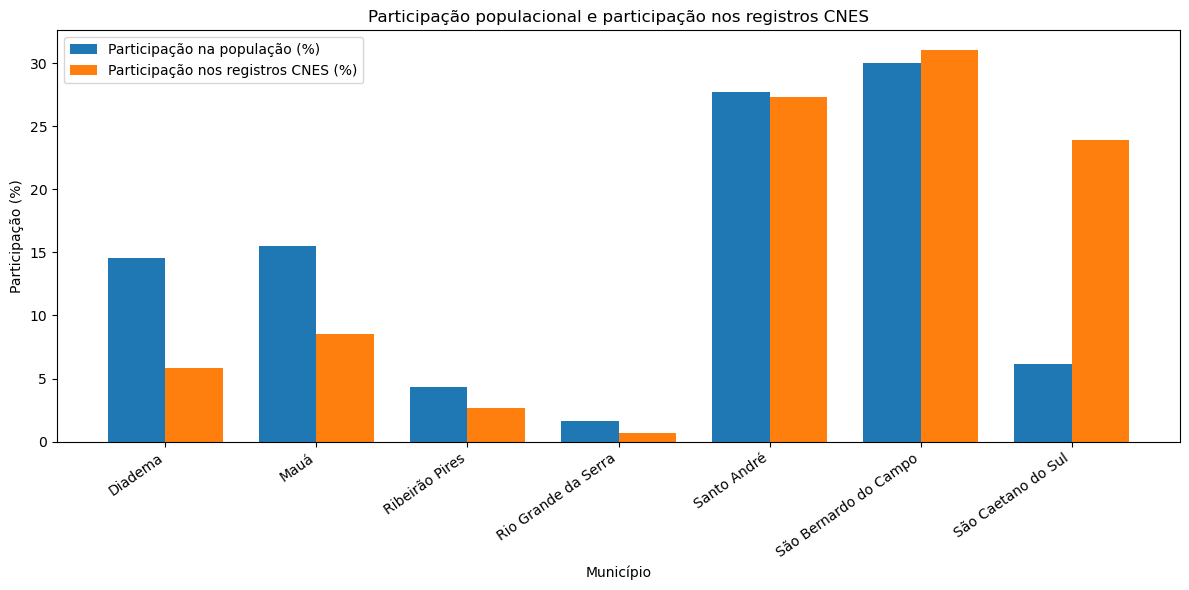

In [27]:
posicoes = np.arange(len(base_distribuicao))
largura = 0.38

plt.figure(figsize=(12, 6))
plt.bar(
    posicoes - largura / 2,
    base_distribuicao["participacao_populacao_pct"],
    width=largura,
    label="Participação na população (%)"
)
plt.bar(
    posicoes + largura / 2,
    base_distribuicao["participacao_registros_cnes_pct"],
    width=largura,
    label="Participação nos registros CNES (%)"
)

plt.title("Participação populacional e participação nos registros CNES")
plt.xlabel("Município")
plt.ylabel("Participação (%)")
plt.xticks(posicoes, base_distribuicao["municipio"], rotation=35, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

## 27. Visualização — registros com atendimento ambulatorial SUS

Compara a quantidade de registros marcados como `SIM` no campo `CO_AMBULATORIAL_SUS`. A leitura deve permanecer restrita a essa característica cadastral.

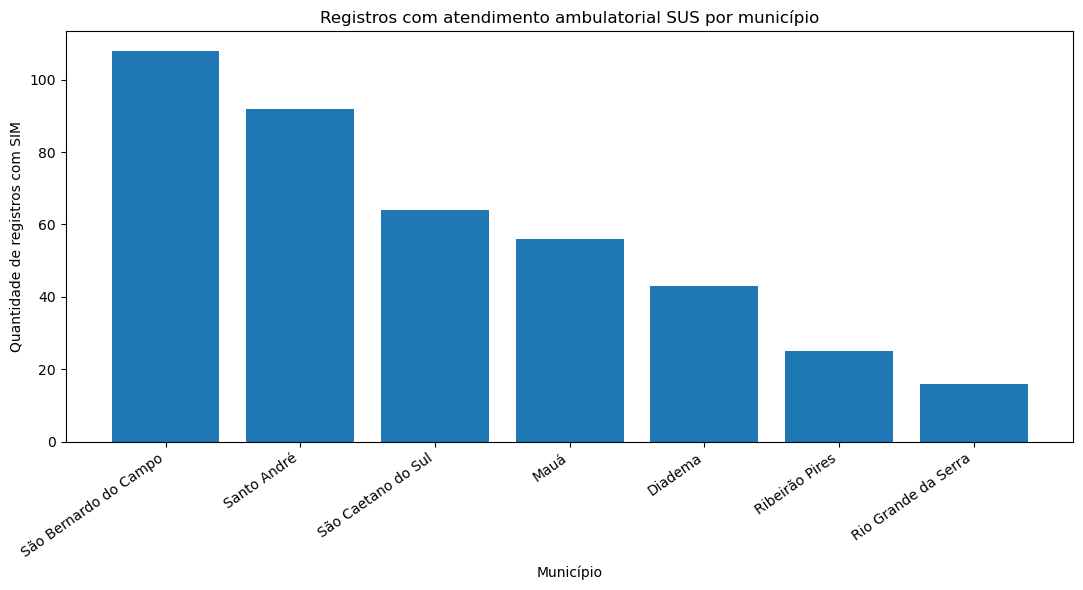

In [28]:
dados_grafico_sus = indicador_ambulatorial_sus.sort_values(
    "registros_ambulatoriais_sus", ascending=False
)

plt.figure(figsize=(11, 6))
plt.bar(
    dados_grafico_sus["municipio"],
    dados_grafico_sus["registros_ambulatoriais_sus"]
)
plt.title("Registros com atendimento ambulatorial SUS por município")
plt.xlabel("Município")
plt.ylabel("Quantidade de registros com SIM")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 28. Técnica exploratória — correlação entre população e registros CNES

Calculamos a correlação de Pearson entre população municipal e quantidade de registros CNES. Como são apenas sete observações e há diferenças estruturais entre municípios, o resultado é descritivo e exploratório: não demonstra causalidade nem suficiência de oferta.

Correlação de Pearson entre população e registros CNES: 0.748


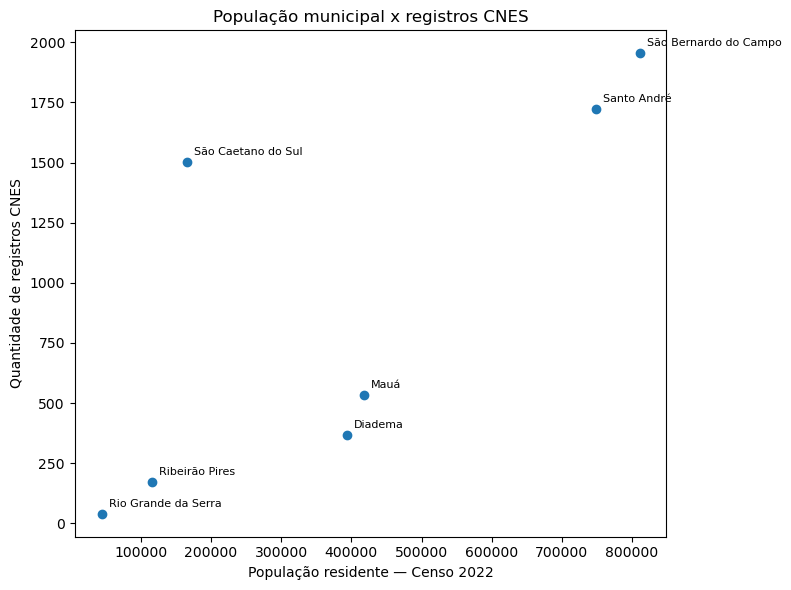

In [29]:
correlacao_pearson = base_municipal[
    ["populacao_2022", "quantidade_registros"]
].corr(method="pearson").iloc[0, 1]

print(
    "Correlação de Pearson entre população e registros CNES:",
    round(correlacao_pearson, 3)
)

plt.figure(figsize=(8, 6))
plt.scatter(
    base_municipal["populacao_2022"],
    base_municipal["quantidade_registros"]
)

for _, linha in base_municipal.iterrows():
    plt.annotate(
        linha["municipio"],
        (linha["populacao_2022"], linha["quantidade_registros"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.title("População municipal x registros CNES")
plt.xlabel("População residente — Censo 2022")
plt.ylabel("Quantidade de registros CNES")
plt.tight_layout()
plt.show()

## 29. Exportação dos novos indicadores

Salva as tabelas complementares para uso no relatório e no protótipo Streamlit.

In [30]:
indicador_esfera.to_csv(
    PASTA_TRATADOS / "indicador_esfera_administrativa.csv",
    index=False, encoding="utf-8-sig"
)

indicador_ambulatorial_sus.to_csv(
    PASTA_TRATADOS / "indicador_ambulatorial_sus.csv",
    index=False, encoding="utf-8-sig"
)

base_distribuicao.to_csv(
    PASTA_TRATADOS / "distribuicao_populacao_registros_cnes.csv",
    index=False, encoding="utf-8-sig"
)

estatistica_descritiva.to_csv(
    PASTA_TRATADOS / "estatistica_descritiva.csv",
    encoding="utf-8-sig"
)

print("Indicadores complementares exportados para:", PASTA_TRATADOS.resolve())

Indicadores complementares exportados para: C:\Users\Caue Almiron\Documents\global_fiap\dados\tratados


## 30. Interpretação preliminar, limitações e continuidade

### O que esta etapa acrescenta

- Descreve a distribuição dos registros segundo a esfera administrativa.
- Mede a proporção de registros com `CO_AMBULATORIAL_SUS = SIM`.
- Compara a participação de cada município na população regional com sua participação nos registros CNES.
- Aplica estatística descritiva e correlação exploratória.
- Produz visualizações adicionais para apoiar a interpretação.

### O que ainda não podemos concluir

- Não podemos afirmar que um município tem acesso melhor ou pior à saúde apenas pela quantidade de registros CNES.
- Não podemos chamar todos os registros municipais/estaduais de estabelecimentos públicos sem validar o conceito e a classificação jurídica.
- Não podemos usar `CO_AMBULATORIAL_SUS` como medida completa de todos os serviços SUS.
- Não podemos afirmar que os estabelecimentos estão ativos sem validar a situação cadastral.
- Não podemos inferir causalidade a partir da correlação entre população e quantidade de registros.
- A população de referência é do Censo 2022, enquanto a extração CNES deve ter sua competência/data de atualização documentada.

### Próxima etapa do projeto

A etapa seguinte deve complementar o cadastro de estabelecimentos com dados de produção/atendimento do SUS ou capacidade instalada (por exemplo, leitos e serviços), para que a plataforma Saúde em Foco aproxime a análise da disponibilidade real de serviços, e não apenas da presença cadastral de estabelecimentos.

## 31. Referências e documentação

- **Portal de Dados Abertos do SUS — CNES Estabelecimentos:** https://dadosabertos.saude.gov.br/dataset/cnes-cadastro-nacional-de-estabelecimentos-de-saude/resource/cd884664-b378-4c6c-854b-6a08faa25d19
- **Wiki CNES — Portal e filtros de consulta:** https://wiki.saude.gov.br/cnes/index.php/Portal_CNES
- **Wiki CNES — Download da base e dicionário de dados:** https://wiki.saude.gov.br/cnes/index.php/Categoria:Consumo_de_informa%C3%A7%C3%B5es_da_Base_Nacional_do_CNES_via_webservice_e_Download_da_Base_de_Dados
- **IBGE/SIDRA — Tabela 4709:** https://sidra.ibge.gov.br/tabela/4709

O Ministério da Saúde informa que o CNES registra estabelecimentos públicos e privados, independentemente de prestarem serviços ao SUS. O portal disponibiliza dimensões distintas para natureza jurídica, gestão e atendimento SUS. Por isso, essas dimensões são analisadas separadamente neste notebook.